# Medical LLM Fine-tuning with QLoRA (4-bit) using Unsloth
**Base model:** Llama 3.2 3B Instruct (4-bit) | **Dataset:** Medical Meadow flashcards (clinical Q&A) | **Method:** QLoRA + SFT

Pehle: `Runtime > Change runtime type > T4 GPU` select karein.

> Disclaimer: Ye sirf educational project hai. Model ke jawab real medical advice nahi hain.

## Step 1: GPU check

In [1]:
!nvidia-smi
import torch
print("CUDA:", torch.cuda.is_available(), "|", torch.cuda.get_device_name(0))

Mon Oct 26 15:35:06 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   66C    P8             12W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## Step 2: Unsloth install

In [2]:
%%capture
!pip install unsloth

## Step 3: Base model 4-bit quantization me load karein

In [3]:
from unsloth import FastLanguageModel
import torch

max_seq_length = 2048
model, tokenizer = FastLanguageModel.from_pretrained(
    model_name = "unsloth/Llama-3.2-3B-Instruct",   # DeepSeek-R1 ke liye: "unsloth/DeepSeek-R1-Distill-Llama-8B"
    max_seq_length = max_seq_length,
    dtype = None,            # auto (T4 -> float16)
    load_in_4bit = True,     # QLoRA: 4-bit NF4 quantization
)

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
Unsloth: xformers is installed but cannot load with torch 2.11.0+cu130 (it was built for 2.10.0+cu128), so PyTorch attention is used instead.
To install a matching xformers, run `unsloth install-kernels xformers`, or `pip uninstall xformers` to hide this. UNSLOTH_ENABLE_LOGGING=1 shows the full error.
🦥 Unsloth Zoo will now patch everything to make training faster!
==((====))==  Unsloth 2026.10.9: Fast Llama patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/254 [00:00<?, ?it/s]

Unsloth: Will load unsloth/Llama-3.2-3B-Instruct-unsloth-bnb-4bit as a legacy tokenizer.


## Step 4: Baseline memory + fine-tuning se PEHLE model ka test

In [4]:
def gpu_mem():
    used = torch.cuda.max_memory_reserved() / 1024**3
    total = torch.cuda.get_device_properties(0).total_memory / 1024**3
    return used, total

used, total = gpu_mem()
print(f"After model load -> peak reserved: {used:.2f} GB / {total:.2f} GB")

def ask(question, max_new_tokens=256):
    FastLanguageModel.for_inference(model)
    msgs = [{"role":"user","content":question}]
    inputs = tokenizer.apply_chat_template(msgs, tokenize=True, add_generation_prompt=True,
                                           return_tensors="pt").to("cuda")
    out = model.generate(input_ids=inputs, max_new_tokens=max_new_tokens,
                         temperature=0.3, do_sample=True, use_cache=True)
    return tokenizer.decode(out[0][inputs.shape[1]:], skip_special_tokens=True)

test_questions = [
    "What are the common symptoms of type 2 diabetes mellitus?",
    "What is the first-line treatment for hypertension in a non-diabetic adult?",
    "Explain the mechanism of action of metformin.",
    "What is the difference between a myocardial infarction and angina pectoris?",
]
print("=== BEFORE FINE-TUNING ===")
before = {}
for q in test_questions:
    before[q] = ask(q)
    print("Q:", q, "\nA:", before[q], "\n" + "-"*80)

After model load -> peak reserved: 2.22 GB / 14.56 GB
=== BEFORE FINE-TUNING ===


Both `max_new_tokens` (=256) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.
Both `max_new_tokens` (=256) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Q: What are the common symptoms of type 2 diabetes mellitus? 
A: The common symptoms of type 2 diabetes mellitus can vary from person to person, but some common signs and symptoms include:

1. Increased thirst and urination: When the body produces more urine, it loses fluids, leading to dehydration and increased thirst.
2. Fatigue: High blood sugar levels can cause fatigue, weakness, and a general feeling of being unwell.
3. Blurred vision: High blood sugar levels can cause the lens in the eye to swell, leading to blurred vision.
4. Slow healing of cuts and wounds: High blood sugar levels can slow down the healing process, making it harder for cuts and wounds to heal.
5. Tingling or numbness in the hands and feet: High blood sugar levels can damage the nerves, causing tingling or numbness in the hands and feet.
6. Recurring skin, gum, or bladder infections: People with type 2 diabetes are more prone to infections, especially in the skin, gums, and bladder.
7. Weight loss: Despite eatin

Both `max_new_tokens` (=256) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Q: What is the first-line treatment for hypertension in a non-diabetic adult? 
A: The first-line treatment for hypertension in a non-diabetic adult is typically lifestyle modifications, followed by pharmacological treatment if necessary.

Lifestyle modifications include:

* A healthy diet (DASH diet)
* Regular physical activity
* Weight loss if overweight or obese
* Stress reduction
* Adequate sleep

If lifestyle modifications are not sufficient to control blood pressure, the next step is to initiate pharmacological treatment with:

* A diuretic (e.g., chlorthiazide or hydrochlorothiazide)
* An ACE inhibitor (e.g., enalapril or lisinopril)
* A calcium channel blocker (e.g., amlodipine or verapamil)
* A beta-blocker (e.g., atenolol or metoprolol)

The American College of Cardiology/American Heart Association (ACC/AHA) guidelines recommend the following initial treatment strategies for hypertension in non-diabetic adults:

* For patients with mild hypertension (130-139/80-89 mmHg): lifes

Both `max_new_tokens` (=256) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Q: Explain the mechanism of action of metformin. 
A: Metformin is a widely used oral antidiabetic medication that belongs to the biguanide class. Its primary mechanism of action involves the inhibition of hepatic gluconeogenesis (glucose production) and the enhancement of insulin sensitivity.

**Mechanism of Action:**

1. **Inhibition of Hepatic Gluconeogenesis:** Metformin inhibits the activity of key enzymes involved in gluconeogenesis, such as phosphoenolpyruvate carboxykinase (PEPCK) and glucose-6-phosphatase (G6Pase). This reduces the production of glucose in the liver, thereby lowering blood glucose levels.
2. **Enhancement of Insulin Sensitivity:** Metformin increases the sensitivity of peripheral tissues (e.g., skeletal muscle and adipose tissue) to insulin. This is achieved by activating AMP-activated protein kinase (AMPK), a key enzyme involved in glucose metabolism. AMPK activation promotes the uptake of glucose by cells and inhibits the production of glucose in the liver.
3

## Step 5: Medical dataset load karein

In [5]:
from datasets import load_dataset

dataset = load_dataset("medalpaca/medical_meadow_medical_flashcards", split="train")
print(dataset)
print(dataset[0])

# Colab free T4 ke liye 5000 samples (time bachane ke liye)
dataset = dataset.shuffle(seed=3407).select(range(5000))

README.md:   0%|          | 0.00/1.24k [00:00<?, ?B/s]

medical_meadow_wikidoc_medical_flashcard(…): reconstructing file:   0%|          |  0.00B / 17.7MB            

medical_meadow_wikidoc_medical_flashcard(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/33955 [00:00<?, ? examples/s]

Dataset({
    features: ['input', 'output', 'instruction'],
    num_rows: 33955
})
{'input': 'What is the relationship between very low Mg2+ levels, PTH levels, and Ca2+ levels?', 'output': 'Very low Mg2+ levels correspond to low PTH levels which in turn results in low Ca2+ levels.', 'instruction': 'Answer this question truthfully'}


## Step 6: Tokenization / chat template formatting

In [6]:
from unsloth.chat_templates import get_chat_template

tokenizer = get_chat_template(tokenizer, chat_template="llama-3.1")

SYSTEM = "You are a helpful medical assistant. Answer clinical questions accurately and concisely."

def to_chat(examples):
    texts = []
    for q, a in zip(examples["input"], examples["output"]):
        convo = [
            {"role":"system","content":SYSTEM},
            {"role":"user","content":q},
            {"role":"assistant","content":a},
        ]
        texts.append(tokenizer.apply_chat_template(convo, tokenize=False, add_generation_prompt=False))
    return {"text": texts}

dataset = dataset.map(to_chat, batched=True)
print(dataset[0]["text"])

Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

<|begin_of_text|><|start_header_id|>system<|end_header_id|>

Cutting Knowledge Date: December 2023
Today Date: 26 July 2024

You are a helpful medical assistant. Answer clinical questions accurately and concisely.<|eot_id|><|start_header_id|>user<|end_header_id|>

What is the role of T-tubules in muscle contraction?<|eot_id|><|start_header_id|>assistant<|end_header_id|>

T-tubules allow for coordinated contraction of muscles.<|eot_id|>


## Step 7: LoRA adapters setup (r=16)

In [7]:
model = FastLanguageModel.get_peft_model(
    model,
    r = 16,
    target_modules = ["q_proj","k_proj","v_proj","o_proj","gate_proj","up_proj","down_proj"],
    lora_alpha = 16,
    lora_dropout = 0,
    bias = "none",
    use_gradient_checkpointing = "unsloth",   # VRAM bachata hai
    random_state = 3407,
    use_rslora = False,
)
model.print_trainable_parameters()

Unsloth 2026.10.9 patched 28 layers with 28 QKV layers, 28 O layers and 28 MLP layers.


Unsloth: compiling each transformer block as one region (LlamaDecoderLayer).
trainable params: 24,313,856 || all params: 3,237,063,680 || trainable%: 0.7511


## Step 8: Trainer config (epoch-based training)

In [8]:
from trl import SFTTrainer, SFTConfig
from unsloth.chat_templates import train_on_responses_only

trainer = SFTTrainer(
    model = model,
    tokenizer = tokenizer,
    train_dataset = dataset,
    args = SFTConfig(
        dataset_text_field = "text",
        per_device_train_batch_size = 2,
        gradient_accumulation_steps = 4,      # effective batch = 8
        warmup_steps = 10,
        num_train_epochs = 1,                 # 2 karna ho to yahan badlein
        learning_rate = 2e-4,
        fp16 = not torch.cuda.is_bf16_supported(),
        bf16 = torch.cuda.is_bf16_supported(),
        logging_steps = 10,
        optim = "adamw_8bit",
        weight_decay = 0.01,
        lr_scheduler_type = "linear",
        seed = 3407,
        output_dir = "outputs",
        report_to = "none",
        dataset_num_proc = 2,
    ),
)

# Sirf assistant ke jawab par loss (question par nahi)
trainer = train_on_responses_only(
    trainer,
    instruction_part = "<|start_header_id|>user<|end_header_id|>\n\n",
    response_part = "<|start_header_id|>assistant<|end_header_id|>\n\n",
)

Unsloth: We found double BOS tokens - we shall remove one automatically.


Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/5000 [00:00<?, ? examples/s]

🦥 Unsloth: Padding-free auto-enabled, enabling faster training.


Map (num_proc=2):   0%|          | 0/5000 [00:00<?, ? examples/s]

## Step 9: Training + memory/performance monitoring

In [9]:
start_gpu_memory = round(torch.cuda.max_memory_reserved() / 1024**3, 3)
print(f"GPU before training: {start_gpu_memory} GB reserved")

trainer_stats = trainer.train()

used_memory = round(torch.cuda.max_memory_reserved() / 1024**3, 3)
used_for_lora = round(used_memory - start_gpu_memory, 3)
total = round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 3)

print(f"Training time: {trainer_stats.metrics['train_runtime']:.0f} sec "
      f"({trainer_stats.metrics['train_runtime']/60:.1f} min)")
print(f"Samples/sec: {trainer_stats.metrics['train_samples_per_second']:.2f}")
print(f"Final train loss: {trainer_stats.metrics['train_loss']:.4f}")
print(f"Peak reserved memory: {used_memory} GB ({used_memory/total*100:.1f}% of {total} GB)")
print(f"Extra memory for training (LoRA): {used_for_lora} GB")

==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 5,000 | Num Epochs = 1 | Total steps = 625
O^O/ \_/ \    Batch size per device = 2 | Gradient accumulation steps = 4
\        /    Data Parallel GPUs = 1 | Total batch size (2 x 4 x 1) = 8
 "-____-"     Trainable parameters = 24,313,856 of 3,237,063,680 (0.75% trained)


GPU before training: 2.426 GB reserved
Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.
Unsloth: Will smartly offload gradients to save VRAM!


Step,Training Loss
10,1.044114
20,0.862945
30,0.887485
40,0.794920
50,0.820686
60,0.792441
70,0.756456
80,0.751057
90,0.747809
100,0.841365


Unsloth: Restored added_tokens_decoder metadata in outputs/checkpoint-500/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in outputs/checkpoint-625/tokenizer_config.json.


Training time: 1227 sec (20.5 min)
Samples/sec: 4.07
Final train loss: 0.7479
Peak reserved memory: 3.656 GB (25.1% of 14.563 GB)
Extra memory for training (LoRA): 1.23 GB


### Loss curve

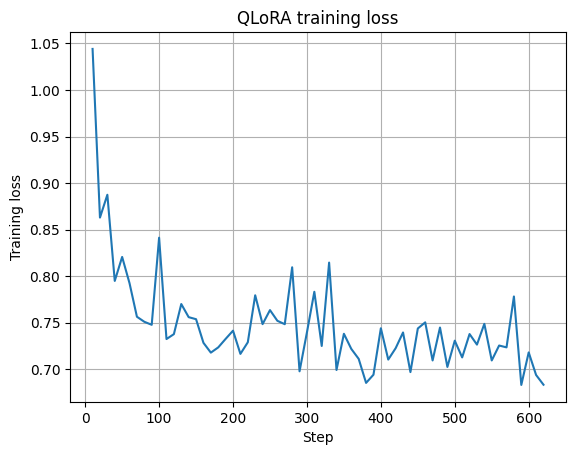

In [10]:
import matplotlib.pyplot as plt
logs = [l for l in trainer.state.log_history if "loss" in l]
plt.plot([l["step"] for l in logs], [l["loss"] for l in logs])
plt.xlabel("Step"); plt.ylabel("Training loss"); plt.title("QLoRA training loss"); plt.grid(True)
plt.show()

## Step 10: Adapter save karein

In [11]:
model.save_pretrained("medical_llama_lora")      # sirf LoRA adapter (~100 MB ya kam)
tokenizer.save_pretrained("medical_llama_lora")

!ls -lh medical_llama_lora
!zip -r medical_llama_lora.zip medical_llama_lora

# Download karein
from google.colab import files
files.download("medical_llama_lora.zip")

# Optional: Google Drive me save
# from google.colab import drive
# drive.mount('/content/drive')
# !cp -r medical_llama_lora /content/drive/MyDrive/

# Optional: Hugging Face Hub par push
# model.push_to_hub("your-username/medical-llama-lora", token="hf_...")

Unsloth: Restored added_tokens_decoder metadata in medical_llama_lora/tokenizer_config.json.


total 110M
-rw-r--r-- 1 root root 1.4K Oct 26 15:59 adapter_config.json
-rw------- 1 root root  93M Oct 26 15:59 adapter_model.safetensors
-rw-r--r-- 1 root root 4.5K Oct 26 15:59 chat_template.jinja
-rw-r--r-- 1 root root 5.2K Oct 26 15:59 README.md
-rw-r--r-- 1 root root  50K Oct 26 15:59 tokenizer_config.json
-rw-r--r-- 1 root root  17M Oct 26 15:59 tokenizer.json
  adding: medical_llama_lora/ (stored 0%)
  adding: medical_llama_lora/tokenizer.json (deflated 85%)
  adding: medical_llama_lora/tokenizer_config.json (deflated 96%)
  adding: medical_llama_lora/README.md (deflated 65%)
  adding: medical_llama_lora/chat_template.jinja (deflated 72%)
  adding: medical_llama_lora/adapter_model.safetensors (deflated 8%)
  adding: medical_llama_lora/adapter_config.json (deflated 60%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Step 11: Fine-tuned model ko NAYE medical queries par test karein

In [12]:
new_questions = [
    "What are the common symptoms of type 2 diabetes mellitus?",
    "What is the first-line treatment for hypertension in a non-diabetic adult?",
    "Explain the mechanism of action of metformin.",
    "What is the difference between a myocardial infarction and angina pectoris?",
    "What are the classic signs of iron deficiency anemia?",
    "Which antibiotic class is commonly used to treat community-acquired pneumonia?",
    "What is the role of insulin in glucose metabolism?",
]
print("=== AFTER FINE-TUNING ===")
for q in new_questions:
    print("Q:", q)
    if q in before: print("BEFORE:", before[q][:400])
    print("AFTER :", ask(q), "\n" + "-"*80)

Both `max_new_tokens` (=256) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


=== AFTER FINE-TUNING ===
Q: What are the common symptoms of type 2 diabetes mellitus?
BEFORE: The common symptoms of type 2 diabetes mellitus can vary from person to person, but some common signs and symptoms include:

1. Increased thirst and urination: When the body produces more urine, it loses fluids, leading to dehydration and increased thirst.
2. Fatigue: High blood sugar levels can cause fatigue, weakness, and a general feeling of being unwell.
3. Blurred vision: High blood sugar lev


Both `max_new_tokens` (=256) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


AFTER : Type 2 diabetes mellitus is a chronic condition that affects the body's ability to regulate blood sugar levels. The common symptoms of type 2 diabetes mellitus include increased thirst and urination, fatigue, blurred vision, slow healing of cuts and wounds, and tingling or numbness in the hands and feet. These symptoms can occur because the body produces more urine in an attempt to flush out excess glucose, which can lead to dehydration and electrolyte imbalances. Other symptoms may include weight loss, skin infections, and yeast infections. If you are experiencing any of these symptoms, it is important to consult with a healthcare provider for proper diagnosis and treatment. 
--------------------------------------------------------------------------------
Q: What is the first-line treatment for hypertension in a non-diabetic adult?
BEFORE: The first-line treatment for hypertension in a non-diabetic adult is typically lifestyle modifications, followed by pharmacological treatme

Both `max_new_tokens` (=256) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


AFTER : The first-line treatment for hypertension in a non-diabetic adult is lifestyle modifications, which include a healthy diet, regular exercise, weight loss, and stress reduction. These lifestyle changes can help to lower blood pressure and improve overall health. If lifestyle modifications are not sufficient to control blood pressure, medications such as ACE inhibitors, calcium channel blockers, or beta-blockers may be prescribed. It is important to work with a healthcare provider to develop a personalized treatment plan for hypertension. 
--------------------------------------------------------------------------------
Q: Explain the mechanism of action of metformin.
BEFORE: Metformin is a widely used oral antidiabetic medication that belongs to the biguanide class. Its primary mechanism of action involves the inhibition of hepatic gluconeogenesis (glucose production) and the enhancement of insulin sensitivity.

**Mechanism of Action:**

1. **Inhibition of Hepatic Gluconeogenesis

... (4 outputs left out)

Both `max_new_tokens` (=256) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


AFTER : The classic signs of iron deficiency anemia are fatigue and weakness, which are often accompanied by a decrease in appetite and a decrease in the size of the red blood cells. 
--------------------------------------------------------------------------------
Q: Which antibiotic class is commonly used to treat community-acquired pneumonia?


Both `max_new_tokens` (=256) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


AFTER : The antibiotic class that is commonly used to treat community-acquired pneumonia is the macrolides. Macrolides are a class of antibiotics that include drugs such as azithromycin and clarithromycin. They work by inhibiting the growth of bacteria that cause pneumonia, and are often used as a first-line treatment for community-acquired pneumonia. Macrolides are generally well-tolerated and have a low risk of side effects, making them a popular choice for treating this condition. However, it is important to note that the choice of antibiotic may depend on factors such as the patient's age, medical history, and the severity of the pneumonia. 
--------------------------------------------------------------------------------
Q: What is the role of insulin in glucose metabolism?
AFTER : Insulin is a hormone that plays a crucial role in glucose metabolism. It is produced by the pancreas and is released in response to high levels of glucose in the blood. Insulin helps to regulate blood gl

## Step 12: Saved adapter ko dobara load karke verify karein

In [13]:
from unsloth import FastLanguageModel
m2, t2 = FastLanguageModel.from_pretrained(model_name="medical_llama_lora",
                                           max_seq_length=2048, load_in_4bit=True)
FastLanguageModel.for_inference(m2)
msgs = [{"role":"user","content":"What are the side effects of ACE inhibitors?"}]
ids = t2.apply_chat_template(msgs, tokenize=True, add_generation_prompt=True, return_tensors="pt").to("cuda")
out = m2.generate(input_ids=ids, max_new_tokens=200, temperature=0.3, do_sample=True)
print(t2.decode(out[0][ids.shape[1]:], skip_special_tokens=True))

==((====))==  Unsloth 2026.10.9: Fast Llama patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/254 [00:00<?, ?it/s]

Unsloth: Will load medical_llama_lora as a legacy tokenizer.
Both `max_new_tokens` (=200) and `max_length`(=131072) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Unsloth: compiling each transformer block as one region (LlamaDecoderLayer).
ACE inhibitors can cause a range of side effects, including cough, dizziness, fatigue, and changes in blood pressure.


## Summary / Report Notes
- **QLoRA:** base weights 4-bit NF4 me frozen, sirf LoRA adapters (r=16) train hue.
- **Memory:** Unsloth gradient checkpointing + 8-bit AdamW se T4 (15 GB) par train ho jata hai.
- **Output:** `medical_llama_lora` adapter folder, baad me kisi bhi Llama-3.2-3B base par load ho sakta hai.
- **Limitation:** chhota dataset, hallucination possible; clinical use ke liye validation zaroori.